# Hierarchical optical classification: four parent states → ARTR / non-ARTR shrub

This notebook **only** analyzes discrete state classification. Stage 1 merges original K5 codes **2 (ARTR)** and **3 (non-ARTR shrub)** into one `SHRUB` class, giving `PBG`, `SHRUB`, `Exotic forb`, `EAG`. Stage 2 is a binary classifier trained **only on training-fold shrub observations**, separating K5 codes 2 versus 3. Its output restores the original five-class K5 labels.

Both feature sets are tested on **identical complete-case observations and identical PlotID-grouped folds**: relative-harmonic IA45 (`β0, A1/β0, A2/A1`) and combined IA75 (`β0, A1, A2, A1/β0, A2/A1`). Existing 8 membership columns are ignored. The notebook compares flat K5, merged K4, hard hierarchy and probability-weighted hierarchy. All tests use **out-of-fold training**; no trained model sees its validation PlotID.

**Interpretation:** The second stage models the original ARTR/non-ARTR K5 labels, *not* an independent field-measured threshold for shrub presence. Held-out class probabilities are not necessarily calibrated; soft routing is a useful exploratory comparison rather than a validated posterior.


In [1]:
# =============================================================================
# 0. IMPORTS / PATHS / SETTINGS
# =============================================================================

from pathlib import Path
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from IPython.display import display

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 280)


# -----------------------------------------------------------------------------
# INPUTS
# -----------------------------------------------------------------------------

VEG_TRAINING_CSV = Path(
    r"A:\NCA_DATA\Validation\Supervised_State_Classification"
    r"\FieldVeg_K2_IA45_Training.csv"
)

K5_ASSIGNMENTS_CSV = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Derived"
    r"\NCA_FCM_K5_m1p33_parent_assignments.csv"
)


K24_ASSIGNMENTS_CSV = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters"
    r"\Subclusters\NCA_K5_species_subclusters_bestSilhouette_DIAGNOSTIC.csv"
)

HARMONIC_ROOT = Path(
    r"A:\NCA_DATA\S2_Harmonics"
)

KEEP_MASK = Path(
    r"C:\NCA_DATA\templates\Masks\NCA_keepMask_v2.tif"
)


# -----------------------------------------------------------------------------
# OUTPUT — completely separate from K8 products
# -----------------------------------------------------------------------------

OUTPUT_DIR = Path(
    r"C:\NCA_DATA\Analysis\PrelimML_RelativeHarmonics_IA45_K5"
)

ALLOW_OVERWRITE = True

if OUTPUT_DIR.exists():
    existing_files = [
        p
        for p in OUTPUT_DIR.rglob("*")
        if p.is_file()
    ]

    if existing_files and not ALLOW_OVERWRITE:
        raise FileExistsError(
            "K5 output directory already contains files. "
            "Stopping rather than overwriting an existing run.\n"
            f"Set ALLOW_OVERWRITE=True only if replacement is intentional.\n\n"
            f"{OUTPUT_DIR}"
        )

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# -----------------------------------------------------------------------------
# ANALYSIS SETTINGS
# -----------------------------------------------------------------------------

# Include 2026 automatically for mapping once its expected K2 raster exists.
# The earlier years remain mandatory in the raster availability checks.
MAP_2026_IF_AVAILABLE = True
RASTER_2026 = HARMONIC_ROOT / "2026" / "2026_K2_InterceptAmpPhase_nobs_RMSE.tif"
YEARS_TO_MAP = list(range(2016, 2026))
if MAP_2026_IF_AVAILABLE and RASTER_2026.exists():
    YEARS_TO_MAP.append(2026)

# The year is considered for training when BOTH optical observations and
# independently assigned K5 labels are available in the source CSVs.
VEG_YEARS = [2016, 2018, 2025, 2026]
EXPECTED_D = 45
EXPECTED_VARIABLES = 15
# Minimum absolute denominator magnitudes (in original feature units).
# Inspect observed denominator distributions before interpreting excluded support.
MIN_ABS_BETA0 = 1e-6
MIN_A1 = 1e-6

K5_CODES = [1, 2, 3, 4, 5]

K5_LABELS = {
    1: "PBG",
    2: "ARTR",
    3: "Non-ARTR shrub",
    4: "Exotic forb",
    5: "EAG",
}

VEG_CLASSES = [
    f"K5::{i}"
    for i in K5_CODES
]

CLASS_TO_CODE = {
    f"K5::{i}": i
    for i in K5_CODES
}

CODE_TO_CLASS = {
    code: cls
    for cls, code in CLASS_TO_CODE.items()
}

RANDOM_STATE = 42
N_SPLITS = 5
COMPRESS = "DEFLATE"
MODEL_FOR_MAPPING = "random_forest"

# Keep False to preserve the same broad support logic as the previous baseline.
FILTER_TRAINING_TO_MASK = False

# Raster mapping switch.
# False = run training/validation/diagnostics only.
# True  = additionally classify YEARS_TO_MAP and write annual map outputs.
RUN_MAPPING = False


print("Vegetation optical table:", VEG_TRAINING_CSV)
print("K5 assignments:          ", K5_ASSIGNMENTS_CSV)
print("K24 assignments:         ", K24_ASSIGNMENTS_CSV)
print("Harmonic root:           ", HARMONIC_ROOT)
print("Mask:                    ", KEEP_MASK)
print("Output:                  ", OUTPUT_DIR)
print("Run raster mapping:      ", RUN_MAPPING)


Vegetation optical table: A:\NCA_DATA\Validation\Supervised_State_Classification\FieldVeg_K2_IA45_Training.csv
K5 assignments:           C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Derived\NCA_FCM_K5_m1p33_parent_assignments.csv
K24 assignments:          C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters\Subclusters\NCA_K5_species_subclusters_bestSilhouette_DIAGNOSTIC.csv
Harmonic root:            A:\NCA_DATA\S2_Harmonics
Mask:                     C:\NCA_DATA\templates\Masks\NCA_keepMask_v2.tif
Output:                   C:\NCA_DATA\Analysis\PrelimML_RelativeHarmonics_IA45_K5
Run raster mapping:       False


In [2]:
# Keep all outputs independent of the original K5 notebooks.
OUTPUT_DIR = Path(r"C:/NCA_DATA/Analysis/PrelimML_Hierarchical_K4toK5_IA45_IA75")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_MAPPING = False  # Set True only after validating the grouped-OOF comparisons.
MODEL_FOR_MAPPING = "extra_trees"
print("Hierarchical output:", OUTPUT_DIR)


Hierarchical output: C:\NCA_DATA\Analysis\PrelimML_Hierarchical_K4toK5_IA45_IA75


In [3]:
# =============================================================================
# 2. LOAD FIELD OPTICAL DATA + K5 LABELS
# =============================================================================

for path in [
    VEG_TRAINING_CSV,
    K5_ASSIGNMENTS_CSV,
]:
    if not path.exists():
        raise FileNotFoundError(path)

veg = pd.read_csv(
    VEG_TRAINING_CSV,
    low_memory=False,
).drop(
    columns=["Unnamed: 0"],
    errors="ignore",
)

k5 = pd.read_csv(
    K5_ASSIGNMENTS_CSV,
    low_memory=False,
).drop(
    columns=["Unnamed: 0"],
    errors="ignore",
)


def normalize_plot_id(x):
    s = str(x).strip()
    if s.endswith(".0"):
        s = s[:-2]
    return s


# Field table uses PlotID in the established supervised workflow.
if "PlotID" not in veg.columns:
    raise KeyError("Field optical table must contain PlotID.")

# K5 assignment table inherited the vegetation master; it normally uses Plot.
if "Plot" in k5.columns:
    K5_PLOT_COL = "Plot"
elif "PlotID" in k5.columns:
    K5_PLOT_COL = "PlotID"
else:
    raise KeyError("K5 assignment table must contain Plot or PlotID.")

for df in [veg, k5]:
    df["Year"] = pd.to_numeric(
        df["Year"],
        errors="coerce",
    )

veg = veg.loc[
    veg["Year"].isin(VEG_YEARS)
].copy()

k5 = k5.loc[
    k5["Year"].isin(VEG_YEARS)
].copy()

veg["Year"] = veg["Year"].astype(int)
k5["Year"] = k5["Year"].astype(int)

veg["_join_plot"] = veg["PlotID"].map(normalize_plot_id)
k5["_join_plot"] = k5[K5_PLOT_COL].map(normalize_plot_id)

if "parent_cluster_k5" not in k5.columns:
    raise KeyError(
        "K5 assignment table must contain parent_cluster_k5."
    )

k5["parent_cluster_k5"] = pd.to_numeric(
    k5["parent_cluster_k5"],
    errors="coerce",
)

k5 = k5.loc[
    k5["parent_cluster_k5"].isin(K5_CODES)
].copy()

k5["parent_cluster_k5"] = k5["parent_cluster_k5"].astype(int)

JOIN_KEYS = ["_join_plot", "Year"]

if veg.duplicated(JOIN_KEYS).any():
    dup = veg.loc[
        veg.duplicated(JOIN_KEYS, keep=False),
        JOIN_KEYS,
    ].head(20)
    raise ValueError(
        "Field optical table contains duplicate normalized Plot-Year keys.\n"
        + dup.to_string(index=False)
    )

if k5.duplicated(JOIN_KEYS).any():
    dup = k5.loc[
        k5.duplicated(JOIN_KEYS, keep=False),
        JOIN_KEYS,
    ].head(20)
    raise ValueError(
        "K5 assignment table contains duplicate normalized Plot-Year keys.\n"
        + dup.to_string(index=False)
    )

k5_keep = [
    "_join_plot",
    "Year",
    "parent_cluster_k5",
]

for c in [
    "max_membership_k5",
    "membership_margin_k5",
]:
    if c in k5.columns:
        k5_keep.append(c)

merged = veg.merge(
    k5[k5_keep],
    on=JOIN_KEYS,
    how="left",
    validate="one_to_one",
    indicator=True,
)

unmatched = merged.loc[
    merged["_merge"].ne("both")
].copy()

print("Field optical rows in vegetation years:", len(veg))
print("Matched to K5 labels:                  ", int((merged["_merge"] == "both").sum()))
print("Unmatched field rows:                  ", len(unmatched))

if len(unmatched) > 0:
    display(
        unmatched[
            ["PlotID", "Year", "_join_plot"]
        ].head(30)
    )

veg = (
    merged.loc[
        merged["_merge"].eq("both")
    ]
    .drop(columns=["_merge"])
    .reset_index(drop=True)
)

veg["parent_cluster_k5"] = veg["parent_cluster_k5"].astype(int)
veg["k5_label"] = veg["parent_cluster_k5"].map(K5_LABELS)

print("\nK5 training-label counts:")
display(
    veg.groupby(
        ["parent_cluster_k5", "k5_label"],
        as_index=False,
    )
    .size()
    .rename(columns={"size": "n"})
)

print("\nYear counts:")
display(
    veg["Year"]
    .value_counts()
    .sort_index()
    .rename("n")
    .to_frame()
)


Field optical rows in vegetation years: 479
Matched to K5 labels:                   479
Unmatched field rows:                   0

K5 training-label counts:


,parent_cluster_k5,k5_label,n
0,1,PBG,109
1,2,ARTR,36
2,3,Non-ARTR shrub,109
3,4,Exotic forb,93
4,5,EAG,132



Year counts:


,n
Year,
2016,255
2018,106
2025,118


In [4]:
# =============================================================================
# 3. ALIGN IA45 AND CONSTRUCT RELATIVE-HARMONIC PREDICTORS
# =============================================================================

def normalize_feature_name(x):
    return str(x).strip().lower()


def parse_ia_feature(name):
    """Parse IA names in either term_variable or variable_term orientation.

    Established raster/field conventions include constant_B2, amp1_B2,
    amp2_B2. Also accepts B2_constant, B2_amp1 and 'intercept' variants.
    """
    key = normalize_feature_name(name)
    term_pattern = r"(?:intercept|constant|beta0|amp(?:litude)?[_-]?[12])"
    for pattern, term_first in (
        (rf"({term_pattern})[_-](.+)", True),
        (rf"(.+)[_-]({term_pattern})", False),
    ):
        match = re.fullmatch(pattern, key)
        if match is None:
            continue
        term, variable = match.groups() if term_first else match.groups()[::-1]
        if not variable:
            continue
        if term in ("intercept", "constant", "beta0"):
            order = "beta0"
        else:
            order = "A1" if term[-1] == "1" else "A2"
        return variable, order
    return None


# Field data are authoritative for the 15 original variable triples.
triples = {}
for col in veg.columns:
    parsed = parse_ia_feature(col)
    if parsed is None:
        continue
    variable, term = parsed
    if term in triples.setdefault(variable, {}):
        raise ValueError(f"Duplicate {term} column for {variable}")
    triples[variable][term] = col

if len(triples) != EXPECTED_VARIABLES or any(
    set(fields) != {"beta0", "A1", "A2"} for fields in triples.values()
):
    raise ValueError(
        "Expected 15 complete beta0/A1/A2 triples; discovered:\n"
        + "Candidate IA columns: " + repr([c for c in veg.columns if re.search(r"constant|intercept|amp|beta0", str(c), re.I)][:60]) + "\n"
        + "\n".join(f"{variable}: {fields}" for variable, fields in triples.items())
    )

VARIABLES = list(triples)
SOURCE_IA_COLS = [
    triples[var][term]
    for var in VARIABLES
    for term in ("beta0", "A1", "A2")
]
FEATURE_NAMES = [
    f"{var}__{term}"
    for var in VARIABLES
    for term in ("beta0", "A1_over_beta0", "A2_over_A1")
]
assert len(SOURCE_IA_COLS) == len(FEATURE_NAMES) == EXPECTED_D


def transform_relative_harmonics(raw):
    """Transform (n,45) original baseline/amplitude data; return (n,45), valid mask."""
    raw = np.asarray(raw, dtype=np.float64)
    if raw.ndim != 2 or raw.shape[1] != EXPECTED_D:
        raise ValueError(f"Expected (n,{EXPECTED_D}) original IA predictors; got {raw.shape}")
    cube = raw.reshape(-1, EXPECTED_VARIABLES, 3)
    beta0, a1, a2 = cube[:, :, 0], cube[:, :, 1], cube[:, :, 2]
    valid = (
        np.isfinite(cube).all(axis=(1, 2))
        & (np.abs(beta0) > MIN_ABS_BETA0).all(axis=1)
        & (a1 > MIN_A1).all(axis=1)
    )
    transformed = np.full((len(raw), EXPECTED_VARIABLES, 3), np.nan)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        transformed[:, :, 0] = beta0
        transformed[:, :, 1] = a1 / beta0
        transformed[:, :, 2] = a2 / a1
    flat = transformed.reshape(-1, EXPECTED_D)
    valid &= np.isfinite(flat).all(axis=1)
    return flat, valid


X_raw = veg[SOURCE_IA_COLS].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)
X_rel_all, valid_rel = transform_relative_harmonics(X_raw)
print(f"Complete cases for ratios: {valid_rel.sum():,} / {len(valid_rel):,}")
print("Excluded observations:", int((~valid_rel).sum()))
print("Excluded by year:")
print(veg.assign(valid_ratio=valid_rel).groupby("Year")["valid_ratio"].agg(["sum", "count"]))

# Keep the response, group identifiers and predictor matrix row-aligned.
veg = veg.loc[valid_rel].reset_index(drop=True)
X_rel = X_rel_all[valid_rel]
y = ("K5::" + veg["parent_cluster_k5"].astype(str)).to_numpy()
groups = veg["PlotID"].astype(str).to_numpy()
print("Training matrix:", X_rel.shape)
print("Classes:", sorted(np.unique(y)))
print("Variables and original source triples:")
for var in VARIABLES:
    print(var, triples[var])


Complete cases for ratios: 479 / 479
Excluded observations: 0
Excluded by year:
      sum  count
Year            
2016  255    255
2018  106    106
2025  118    118
Training matrix: (479, 45)
Classes: ['K5::1', 'K5::2', 'K5::3', 'K5::4', 'K5::5']
Variables and original source triples:
b2 {'beta0': 'constant_B2', 'A1': 'amp1_B2', 'A2': 'amp2_B2'}
b3 {'beta0': 'constant_B3', 'A1': 'amp1_B3', 'A2': 'amp2_B3'}
b4 {'beta0': 'constant_B4', 'A1': 'amp1_B4', 'A2': 'amp2_B4'}
b5 {'beta0': 'constant_B5', 'A1': 'amp1_B5', 'A2': 'amp2_B5'}
b6 {'beta0': 'constant_B6', 'A1': 'amp1_B6', 'A2': 'amp2_B6'}
b7 {'beta0': 'constant_B7', 'A1': 'amp1_B7', 'A2': 'amp2_B7'}
b8 {'beta0': 'constant_B8', 'A1': 'amp1_B8', 'A2': 'amp2_B8'}
b8a {'beta0': 'constant_B8A', 'A1': 'amp1_B8A', 'A2': 'amp2_B8A'}
b11 {'beta0': 'constant_B11', 'A1': 'amp1_B11', 'A2': 'amp2_B11'}
b12 {'beta0': 'constant_B12', 'A1': 'amp1_B12', 'A2': 'amp2_B12'}
ndvi {'beta0': 'constant_NDVI', 'A1': 'amp1_NDVI', 'A2': 'amp2_NDVI'}
ndmi {'beta0

In [5]:
# =============================================================================
# 4. OPTIONAL TRAINING MASK FILTER
# =============================================================================


def mask_keep_for_points(
    table,
    x_col,
    y_col,
    mask_path,
):
    keep_flags = []

    with rasterio.open(mask_path) as src:
        nodata = src.nodata

        coords = list(
            zip(
                table[x_col].astype(float),
                table[y_col].astype(float),
            )
        )

        for value in src.sample(
            coords,
            indexes=1,
            masked=False,
        ):
            v = value[0]
            valid = np.isfinite(v)

            if nodata is not None:
                valid &= not np.isclose(v, nodata)

            keep_flags.append(
                bool(valid and v > 0)
            )

    return np.asarray(
        keep_flags,
        dtype=bool,
    )


if FILTER_TRAINING_TO_MASK:
    required_xy = ["Easting", "Northing"]

    if not all(c in veg.columns for c in required_xy):
        raise KeyError(
            "Mask filtering requires Easting and Northing in vegetation table."
        )

    keep_training = mask_keep_for_points(
        veg,
        "Easting",
        "Northing",
        KEEP_MASK,
    )

    print(
        "Rows retained by mapping mask:",
        int(keep_training.sum()),
        "/",
        len(veg),
    )

    veg = veg.loc[keep_training].copy().reset_index(drop=True)
    X_rel = X_rel[keep_training]
    y = y[keep_training]
    groups = groups[keep_training]
    years_veg = years_veg[keep_training]

print("Final modeling rows:", len(veg))


Final modeling rows: 479


In [6]:
# Combined IA75 from the same 45 raw inputs and the exact IA45-valid rows.
# X_rel is already filtered and shares row alignment with veg.
raw_aligned = veg[SOURCE_IA_COLS].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
assert raw_aligned.shape == (len(veg), 45)
raw_cube = raw_aligned.reshape(-1, EXPECTED_VARIABLES, 3)
rel_cube = X_rel.reshape(-1, EXPECTED_VARIABLES, 3)
X_75 = np.concatenate([raw_cube, rel_cube[:, :, 1:]], axis=2).reshape(len(veg), 75)
assert np.isfinite(X_75).all() and np.isfinite(X_rel).all()
FEATURE_NAMES_75 = [f"{v}__{t}" for v in VARIABLES
                    for t in ("beta0", "A1", "A2", "A1_over_beta0", "A2_over_A1")]
FEATURE_SETS = {"relative_IA45": X_rel, "raw_plus_ratios_IA75": X_75}

# Labels: original 1=PBG, 2=ARTR, 3=non-ARTR shrub, 4=exotic forb, 5=EAG.
y5 = veg["parent_cluster_k5"].to_numpy(dtype=int)
y4 = np.where(np.isin(y5, [2, 3]), 2, y5)
K4_CODES = [1, 2, 4, 5]
K4_LABELS = {1: "PBG", 2: "SHRUB", 4: "Exotic forb", 5: "EAG"}
K5_LABELS = {1: "PBG", 2: "ARTR", 3: "Non-ARTR shrub", 4: "Exotic forb", 5: "EAG"}
assert set(np.unique(y5)) == set(range(1, 6))
assert set(np.unique(y4)) == set(K4_CODES)
print("Common sample size:", len(y5))
print(pd.crosstab(pd.Series(y4, name="K4"), pd.Series(y5, name="K5")))


Common sample size: 479
K5    1   2    3   4    5
K4                       
1   109   0    0   0    0
2     0  36  109   0    0
4     0   0    0  93    0
5     0   0    0   0  132


In [7]:
# =============================================================================
# 5. MODELS
# =============================================================================

MODELS = {
    "elastic_net_logistic": Pipeline([
        (
            "scale",
            StandardScaler(),
        ),
        (
            "model",
            LogisticRegression(
                solver="saga",
                penalty="elasticnet",
                l1_ratio=0.5,
                C=1.0,
                class_weight="balanced",
                max_iter=10000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]),

    "random_forest": RandomForestClassifier(
        n_estimators=800,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        bootstrap=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),

    "extra_trees": ExtraTreesClassifier(
        n_estimators=800,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        bootstrap=False,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}


def score_predictions(
    y_true,
    y_pred,
):
    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred,
        ),
        "macro_precision": precision_score(
            y_true,
            y_pred,
            labels=VEG_CLASSES,
            average="macro",
            zero_division=0,
        ),
        "macro_recall": recall_score(
            y_true,
            y_pred,
            labels=VEG_CLASSES,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=VEG_CLASSES,
            average="macro",
            zero_division=0,
        ),
    }


In [8]:
# Strict group separation in every outer split; same folds for IA45 and IA75.
# Stratification follows four-class parents, which are the first-stage target.
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
CV_SPLITS = list(cv.split(X_rel, y4, groups))
for fold, (train, test) in enumerate(CV_SPLITS, 1):
    assert set(groups[train]).isdisjoint(set(groups[test])), f"PlotID leakage, fold {fold}"
    if len(set(y4[train])) < 4 or len(set(y5[train][np.isin(y5[train], [2,3])])) < 2:
        raise ValueError(f"Fold {fold} lacks a stage-1 parent or a shrub subtype")
    print(f"Fold {fold}: train={len(train)}, test={len(test)}, "
          f"train shrubs={np.isin(y5[train], [2,3]).sum()}")


Fold 1: train=388, test=91, train shrubs=112
Fold 2: train=383, test=96, train shrubs=120
Fold 3: train=386, test=93, train shrubs=115
Fold 4: train=380, test=99, train shrubs=113
Fold 5: train=379, test=100, train shrubs=120


In [9]:
# Hierarchy functions. Probabilities are aligned to explicit K4/K5 codes,
# regardless of sklearn's internal class ordering.
def aligned_proba(model, X, classes):
    out = np.zeros((len(X), len(classes)), dtype=float)
    got = model.predict_proba(X)
    for j, label in enumerate(model.classes_):
        out[:, classes.index(int(label))] = got[:, j]
    return out


def fit_hierarchy(template, X, y5_train):
    four = np.where(np.isin(y5_train, [2, 3]), 2, y5_train)
    parent = clone(template).fit(X, four)
    is_shrub = np.isin(y5_train, [2, 3])
    if set(y5_train[is_shrub]) != {2, 3}:
        raise ValueError("Both shrub subclasses required for conditional fit")
    child = clone(template).fit(X[is_shrub], y5_train[is_shrub])
    return parent, child


def predict_hierarchy(parent, child, X):
    p4 = aligned_proba(parent, X, K4_CODES)
    p_child = aligned_proba(child, X, [2, 3])
    # P(K5=k|X) = P(K4=shrub|X) * P(k|X, shrub) for shrub children.
    p5 = np.column_stack((p4[:, 0],
                          p4[:, 1] * p_child[:, 0],
                          p4[:, 1] * p_child[:, 1],
                          p4[:, 2], p4[:, 3]))
    assert np.allclose(p5.sum(axis=1), 1.0, atol=1e-8)
    soft = np.asarray([1, 2, 3, 4, 5])[np.argmax(p5, axis=1)]
    hard4 = np.asarray(K4_CODES)[np.argmax(p4, axis=1)]
    hard = np.where(hard4 == 2,
                    np.asarray([2, 3])[np.argmax(p_child, axis=1)], hard4)
    return hard4, hard, soft, p4, p5


def metrics(actual, pred, labels):
    return {"n": len(actual),
            "accuracy": accuracy_score(actual, pred),
            "balanced_accuracy": balanced_accuracy_score(actual, pred),
            "macro_precision": precision_score(actual, pred, labels=labels, average="macro", zero_division=0),
            "macro_f1": f1_score(actual, pred, labels=labels, average="macro", zero_division=0)}


In [10]:
# Three-way benchmark, same test rows and folds for every model / feature set.
# No K24 fitting is performed here.
RESULTS = []
OOF = {}
for feature_name, X in FEATURE_SETS.items():
    for model_name in ["extra_trees", "random_forest"]:
        template = MODELS[model_name]
        predictions = {key: np.full(len(y5), -1, dtype=int)
                       for key in ["flat_K5", "parent_K4", "hierarchy_hard_K5", "hierarchy_soft_K5"]}
        p4_oof = np.full((len(y5), 4), np.nan)
        p5_oof = np.full((len(y5), 5), np.nan)
        shrub_oracle_pred = np.full(len(y5), -1, dtype=int)
        fold_rows = []
        for fold, (train, test) in enumerate(CV_SPLITS, 1):
            flat = clone(template).fit(X[train], y5[train])
            parent, child = fit_hierarchy(template, X[train], y5[train])
            p4, hard, soft, probs4, probs5 = predict_hierarchy(parent, child, X[test])
            predictions["flat_K5"][test] = flat.predict(X[test]).astype(int)
            predictions["parent_K4"][test] = p4
            predictions["hierarchy_hard_K5"][test] = hard
            predictions["hierarchy_soft_K5"][test] = soft
            p4_oof[test], p5_oof[test] = probs4, probs5
            # Oracle-child diagnostic: evaluate child model ONLY where actual parent is shrub.
            shrub_test = test[np.isin(y5[test], [2, 3])]
            if len(shrub_test):
                shrub_oracle_pred[shrub_test] = child.predict(X[shrub_test]).astype(int)
            for scenario, pred in predictions.items():
                labels = K4_CODES if scenario == "parent_K4" else [1, 2, 3, 4, 5]
                truth = y4 if scenario == "parent_K4" else y5
                fold_rows.append({"features": feature_name, "model": model_name,
                                  "scenario": scenario, "fold": fold,
                                  **metrics(truth[test], pred[test], labels)})
        for scenario, pred in predictions.items():
            assert np.all(pred >= 0), f"Unfilled OOF predictions: {scenario}"
            truth = y4 if scenario == "parent_K4" else y5
            labels = K4_CODES if scenario == "parent_K4" else [1, 2, 3, 4, 5]
            RESULTS.append({"features": feature_name, "model": model_name,
                            "scenario": scenario, **metrics(truth, pred, labels)})
        shrub_mask = np.isin(y5, [2, 3])
        RESULTS.append({"features": feature_name, "model": model_name,
                        "scenario": "oracle_shrub_child_only",
                        **metrics(y5[shrub_mask], shrub_oracle_pred[shrub_mask], [2, 3])})
        key = (feature_name, model_name)
        OOF[key] = {**predictions, "p4": p4_oof, "p5": p5_oof,
                    "oracle_child": shrub_oracle_pred,
                    "fold_rows": pd.DataFrame(fold_rows)}
        OOF[key]["fold_rows"].to_csv(OUTPUT_DIR / f"{feature_name}_{model_name}_fold_metrics.csv", index=False)

results = pd.DataFrame(RESULTS)
results.to_csv(OUTPUT_DIR / "hierarchical_groupedOOF_metrics.csv", index=False)
display(results.sort_values(["features", "model", "scenario"]).round(4))


,features,model,scenario,n,accuracy,balanced_accuracy,macro_precision,macro_f1
10,raw_plus_ratios_IA75,extra_trees,flat_K5,479,0.6326,0.5929,0.6133,0.5989
12,raw_plus_ratios_IA75,extra_trees,hierarchy_hard_K5,479,0.6242,0.5707,0.5886,0.5752
13,raw_plus_ratios_IA75,extra_trees,hierarchy_soft_K5,479,0.6430,0.5791,0.6028,0.5801
14,raw_plus_ratios_IA75,extra_trees,oracle_shrub_child_only,145,0.7586,0.5883,0.6592,0.5960
11,raw_plus_ratios_IA75,extra_trees,parent_K4,479,0.6848,0.6782,0.6781,0.6780
15,raw_plus_ratios_IA75,random_forest,flat_K5,479,0.6054,0.5467,0.5725,0.5497
17,raw_plus_ratios_IA75,random_forest,hierarchy_hard_K5,479,0.6117,0.5513,0.5759,0.5550
18,raw_plus_ratios_IA75,random_forest,hierarchy_soft_K5,479,0.6263,0.5607,0.5988,0.5621
19,raw_plus_ratios_IA75,random_forest,oracle_shrub_child_only,145,0.7655,0.5743,0.6826,0.5756
16,raw_plus_ratios_IA75,random_forest,parent_K4,479,0.6701,0.6621,0.6619,0.6618


In [11]:
# Confusion matrices / classification reports for each feature set.
for key, pred in OOF.items():
    feature_name, model_name = key
    print("\n", feature_name, model_name)
    for scenario, labels, target, names in [
        ("parent_K4", K4_CODES, y4, K4_LABELS),
        ("flat_K5", [1,2,3,4,5], y5, K5_LABELS),
        ("hierarchy_hard_K5", [1,2,3,4,5], y5, K5_LABELS),
        ("hierarchy_soft_K5", [1,2,3,4,5], y5, K5_LABELS)]:
        print("\n", scenario)
        cm = pd.DataFrame(confusion_matrix(target, pred[scenario], labels=labels),
                          index=["true " + names[i] for i in labels],
                          columns=["pred " + names[i] for i in labels])
        display(cm)
        cm.to_csv(OUTPUT_DIR / f"{feature_name}_{model_name}_{scenario}_confusion.csv")
    shrub_mask = np.isin(y5, [2,3])
    print("Conditional shrub prediction, held-out true shrubs only:")
    print(classification_report(y5[shrub_mask], pred["oracle_child"][shrub_mask],
                                labels=[2,3], target_names=["ARTR", "Non-ARTR shrub"], zero_division=0))
    pd.DataFrame({"PlotID": veg["PlotID"], "Year": veg["Year"],
                  "true_K5": y5, "true_K4": y4,
                  **{s:pred[s] for s in ("flat_K5","parent_K4","hierarchy_hard_K5","hierarchy_soft_K5")},
                  **{f"prob_K5_{c}":pred["p5"][:,j] for j,c in enumerate([1,2,3,4,5])}}).to_csv(
                      OUTPUT_DIR / f"{feature_name}_{model_name}_OOF_predictions.csv",index=False)



 relative_IA45 extra_trees

 parent_K4


,pred PBG,pred SHRUB,pred Exotic forb,pred EAG
true PBG,63,14,16,16
true SHRUB,17,103,13,12
true Exotic forb,12,13,66,2
true EAG,16,12,5,99



 flat_K5


,pred PBG,pred ARTR,pred Non-ARTR shrub,pred Exotic forb,pred EAG
true PBG,66,0,9,17,17
true ARTR,1,12,14,6,3
true Non-ARTR shrub,15,9,61,13,11
true Exotic forb,13,2,5,70,3
true EAG,17,4,7,6,98



 hierarchy_hard_K5


,pred PBG,pred ARTR,pred Non-ARTR shrub,pred Exotic forb,pred EAG
true PBG,63,0,14,16,16
true ARTR,1,10,18,5,2
true Non-ARTR shrub,16,8,67,8,10
true Exotic forb,12,2,11,66,2
true EAG,16,4,8,5,99


... (23 outputs left out)

,pred PBG,pred ARTR,pred Non-ARTR shrub,pred Exotic forb,pred EAG
true PBG,60,1,14,14,20
true ARTR,1,7,23,2,3
true Non-ARTR shrub,14,5,68,10,12
true Exotic forb,16,1,11,60,5
true EAG,13,3,11,7,98



 hierarchy_soft_K5


,pred PBG,pred ARTR,pred Non-ARTR shrub,pred Exotic forb,pred EAG
true PBG,64,0,10,15,20
true ARTR,2,6,17,8,3
true Non-ARTR shrub,16,4,63,11,15
true Exotic forb,16,1,6,65,5
true EAG,14,1,8,7,102


Conditional shrub prediction, held-out true shrubs only:
                precision    recall  f1-score   support

          ARTR       0.58      0.19      0.29        36
Non-ARTR shrub       0.78      0.95      0.86       109

      accuracy                           0.77       145
     macro avg       0.68      0.57      0.58       145
  weighted avg       0.73      0.77      0.72       145



## Diagnostics and limitations

- K4 and K5 accuracies are **different classification questions**; compare the flat K5 against the reconstructed hard/soft K5 directly. The merged K4 score estimates detection of the four broad *cluster labels*, not physical shrub presence.
- `oracle_shrub_child_only` evaluates the shrub discriminator on **observations known to be shrubs in the held-out fold**; it is an upper-level diagnostic, not an operational routing score. Small ARTR support may make results unstable.
- All performance estimates use PlotID-held-out folds. Nearby plots or repeated spatial nodes can still be correlated; consider node/spatial block or year holdout in a subsequent analysis.
- Soft routing multiplies classifier output scores as conditional probabilities, but neither classifier is probability-calibrated. Treat these outputs as **relative scores**, not ecological posterior uncertainty.
- No oversampling or bootstrap is applied, so this experiment isolates architecture and feature representation.


In [12]:
# Optional: fit each two-stage model to all labeled observations for future mapping.
# Final models cannot serve as a held-out accuracy estimate.
FINAL_HIERARCHIES = {}
for feature_name, X in FEATURE_SETS.items():
    FINAL_HIERARCHIES[feature_name] = fit_hierarchy(MODELS[MODEL_FOR_MAPPING], X, y5)
print("Final two-stage models trained for:", list(FINAL_HIERARCHIES))


Final two-stage models trained for: ['relative_IA45', 'raw_plus_ratios_IA75']


In [13]:
# Optional annual raster mapping: generated maps are K4 and reconstructed K5.
# Existing K2 source raster band alignment and denominator handling are reused.
# This is off by default, and no existing K5 raster products are overwritten.
def annual_k2_path(year):
    return HARMONIC_ROOT / str(year) / f"{year}_K2_InterceptAmpPhase_nobs_RMSE.tif"


def transform_raster_source(raw45, feature_set):
    rel, good = transform_relative_harmonics(raw45)
    if feature_set == "relative_IA45":
        return rel, good
    raw = raw45.reshape(-1, 15, 3)
    rel = rel.reshape(-1, 15, 3)
    x = np.concatenate([raw, rel[:,:,1:]], axis=2).reshape(-1,75)
    return x, good & np.isfinite(x).all(axis=1)


def map_hierarchy(year, feature_set="relative_IA45"):
    import rasterio
    from rasterio.vrt import WarpedVRT
    from rasterio.enums import Resampling
    parent, child = FINAL_HIERARCHIES[feature_set]
    source_path = annual_k2_path(year)
    prefix = OUTPUT_DIR / f"{year}_{feature_set}_hierarchy"
    with rasterio.open(source_path) as src, rasterio.open(KEEP_MASK) as keep_src:
        descriptions = [(d or "").strip().lower() for d in src.descriptions]
        lookup = {desc: i+1 for i,desc in enumerate(descriptions)}
        missing = [name for name in SOURCE_IA_COLS if name.lower() not in lookup]
        if missing: raise KeyError(f"Raster {year} lacks expected IA bands: {missing}")
        indexes = [lookup[name.lower()] for name in SOURCE_IA_COLS]
        same_grid = (src.crs == keep_src.crs and src.transform == keep_src.transform
                     and src.shape == keep_src.shape)
        vrt = None if same_grid else WarpedVRT(keep_src, crs=src.crs,
                  transform=src.transform, width=src.width, height=src.height,
                  resampling=Resampling.nearest)
        mask = keep_src if same_grid else vrt
        profile = src.profile.copy()
        profile.update(count=1, dtype="uint8", nodata=0, compress="DEFLATE", BIGTIFF="IF_SAFER")
        paths = {k:Path(str(prefix) + "_" + k + ".tif") for k in
                 ["parent_K4", "hard_K5", "soft_K5"]}
        for path in paths.values():
            if path.exists() and not ALLOW_OVERWRITE: raise FileExistsError(path)
        try:
            with rasterio.open(paths["parent_K4"], "w", **profile) as out4, \
                 rasterio.open(paths["hard_K5"], "w", **profile) as outh, \
                 rasterio.open(paths["soft_K5"], "w", **profile) as outs:
                for _, window in src.block_windows(1):
                    bands = src.read(indexes, window=window, masked=True).astype(float)
                    keep = mask.read(1, window=window, masked=True)
                    valid = ~np.ma.getmaskarray(bands).any(axis=0)
                    valid &= (~np.ma.getmaskarray(keep)) & (np.ma.filled(keep,0)>0)
                    h,w = valid.shape
                    raw = np.ma.filled(bands, np.nan).reshape(45,-1).T
                    candidates = np.flatnonzero(valid.ravel())
                    maps = [np.zeros(h*w, dtype="uint8") for _ in range(3)]
                    if len(candidates):
                        X, ok = transform_raster_source(raw[candidates], feature_set)
                        good_ids = candidates[ok]
                        if len(good_ids):
                            k4, hard, soft, _, _ = predict_hierarchy(parent,child,X[ok])
                            for layer, values in zip(maps,[k4,hard,soft]):
                                layer[good_ids] = values.astype("uint8")
                    for dst,layer in zip([out4,outh,outs],maps):
                        dst.write(layer.reshape(h,w),1,window=window)
        finally:
            if vrt is not None: vrt.close()
    return paths

if RUN_MAPPING:
    for feature_name in FEATURE_SETS:
        for year in YEARS_TO_MAP:
            path = annual_k2_path(year)
            if path.exists():
                print(year,feature_name,map_hierarchy(year,feature_name))
            else:
                print("Skipping unavailable annual imagery:",path)
else:
    print("Mapping disabled. Set RUN_MAPPING=True in the settings cell when ready.")


Mapping disabled. Set RUN_MAPPING=True in the settings cell when ready.


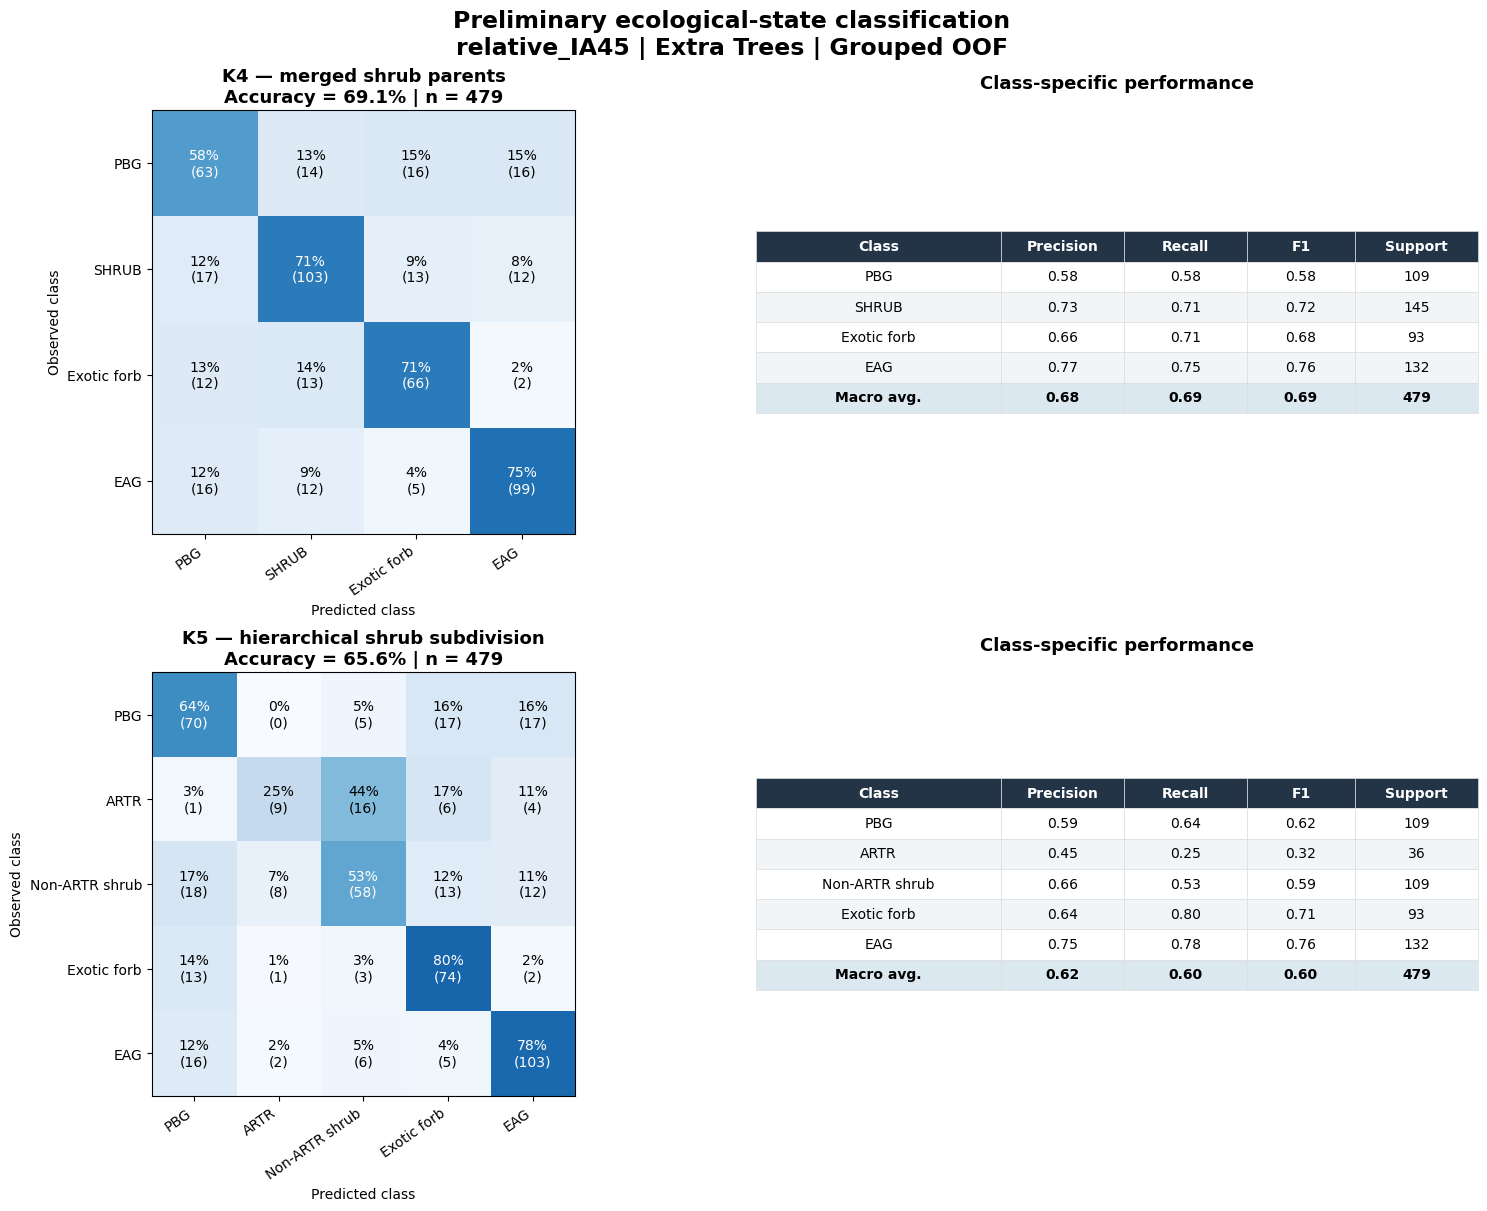

In [14]:

# ============================================================
# PRESENTATION FIGURE — K4 AND K5 CONFUSION + CLASS METRICS
# ============================================================

from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FEATURE = "relative_IA45"  # or "raw_plus_ratios_IA75"
MODEL = "extra_trees"
K5_SCENARIO = "hierarchy_soft_K5"

pred = OOF[(FEATURE, MODEL)]

comparisons = [
    ("K4 — merged shrub parents",
     y4, pred["parent_K4"], K4_CODES, K4_LABELS),
    ("K5 — hierarchical shrub subdivision",
     y5, pred[K5_SCENARIO], K5_CODES, K5_LABELS),
]

fig, axes = plt.subplots(
    2, 2, figsize=(15, 12),
    gridspec_kw={"width_ratios": [1.15, 1.1],
                 "height_ratios": [1, 1]},
    constrained_layout=True
)

for row, (title, actual, predicted, codes, names) in enumerate(comparisons):

    labels = [names[c] for c in codes]
    cm = confusion_matrix(actual, predicted, labels=codes)
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

    accuracy = np.trace(cm) / cm.sum()

    # ---- Confusion matrix ----
    ax = axes[row, 0]

    im = ax.imshow(
        cm_norm, cmap="Blues",
        vmin=0, vmax=1, aspect="equal"
    )

    for i in range(len(codes)):
        for j in range(len(codes)):
            value = cm_norm[i, j]
            count = cm[i, j]
            ax.text(
                j, i, f"{value:.0%}\n({count})",
                ha="center", va="center",
                fontsize=10,
                color="white" if value > 0.5 else "black"
            )

    ax.set_xticks(range(len(codes)), labels, rotation=35, ha="right")
    ax.set_yticks(range(len(codes)), labels)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Observed class")
    ax.set_title(
        f"{title}\nAccuracy = {accuracy:.1%} | n = {len(actual)}",
        fontsize=13, fontweight="bold"
    )

    # ---- Class metrics table ----
    precision, recall, f1, support = precision_recall_fscore_support(
        actual, predicted, labels=codes, zero_division=0
    )

    metrics_df = pd.DataFrame({
        "Class": labels,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "n": support
    })

    summary = pd.DataFrame([{
        "Class": "Macro avg.",
        "Precision": precision.mean(),
        "Recall": recall.mean(),
        "F1": f1.mean(),
        "n": support.sum()
    }])

    metrics_df = pd.concat([metrics_df, summary], ignore_index=True)

    ax_table = axes[row, 1]
    ax_table.axis("off")

    table_data = [
        [
            r["Class"],
            f"{r['Precision']:.2f}",
            f"{r['Recall']:.2f}",
            f"{r['F1']:.2f}",
            f"{int(r['n'])}"
        ]
        for _, r in metrics_df.iterrows()
    ]

    tbl = ax_table.table(
        cellText=table_data,
        colLabels=["Class", "Precision", "Recall", "F1", "Support"],
        cellLoc="center",
        colLoc="center",
        loc="center",
        colWidths=[0.34, 0.17, 0.17, 0.15, 0.17]
    )

    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 1.8)

    for (r, c), cell in tbl.get_celld().items():
        cell.set_edgecolor("#DDDDDD")
        cell.set_linewidth(0.5)

        if r == 0:
            cell.set_facecolor("#243447")
            cell.set_text_props(color="white", weight="bold")
        elif r == len(table_data):
            cell.set_facecolor("#DCE8F0")
            cell.set_text_props(weight="bold")
        elif r % 2 == 0:
            cell.set_facecolor("#F2F5F7")
        else:
            cell.set_facecolor("white")

    ax_table.set_title(
        "Class-specific performance",
        fontsize=13, fontweight="bold", pad=16
    )

    # Export the exact metrics used in the figure.
    metrics_df.to_csv(
        OUTPUT_DIR / f"{FEATURE}_{MODEL}_figure_{'K4' if row == 0 else 'K5'}_metrics.csv",
        index=False
    )

fig.suptitle(
    f"Preliminary ecological-state classification\n"
    f"{FEATURE} | {MODEL.replace('_', ' ').title()} | Grouped OOF",
    fontsize=17, fontweight="bold"
)

fig.savefig(
    OUTPUT_DIR / f"{FEATURE}_{MODEL}_K4_K5_comparison.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    OUTPUT_DIR / f"{FEATURE}_{MODEL}_K4_K5_comparison.svg",
    bbox_inches="tight"
)

plt.show()


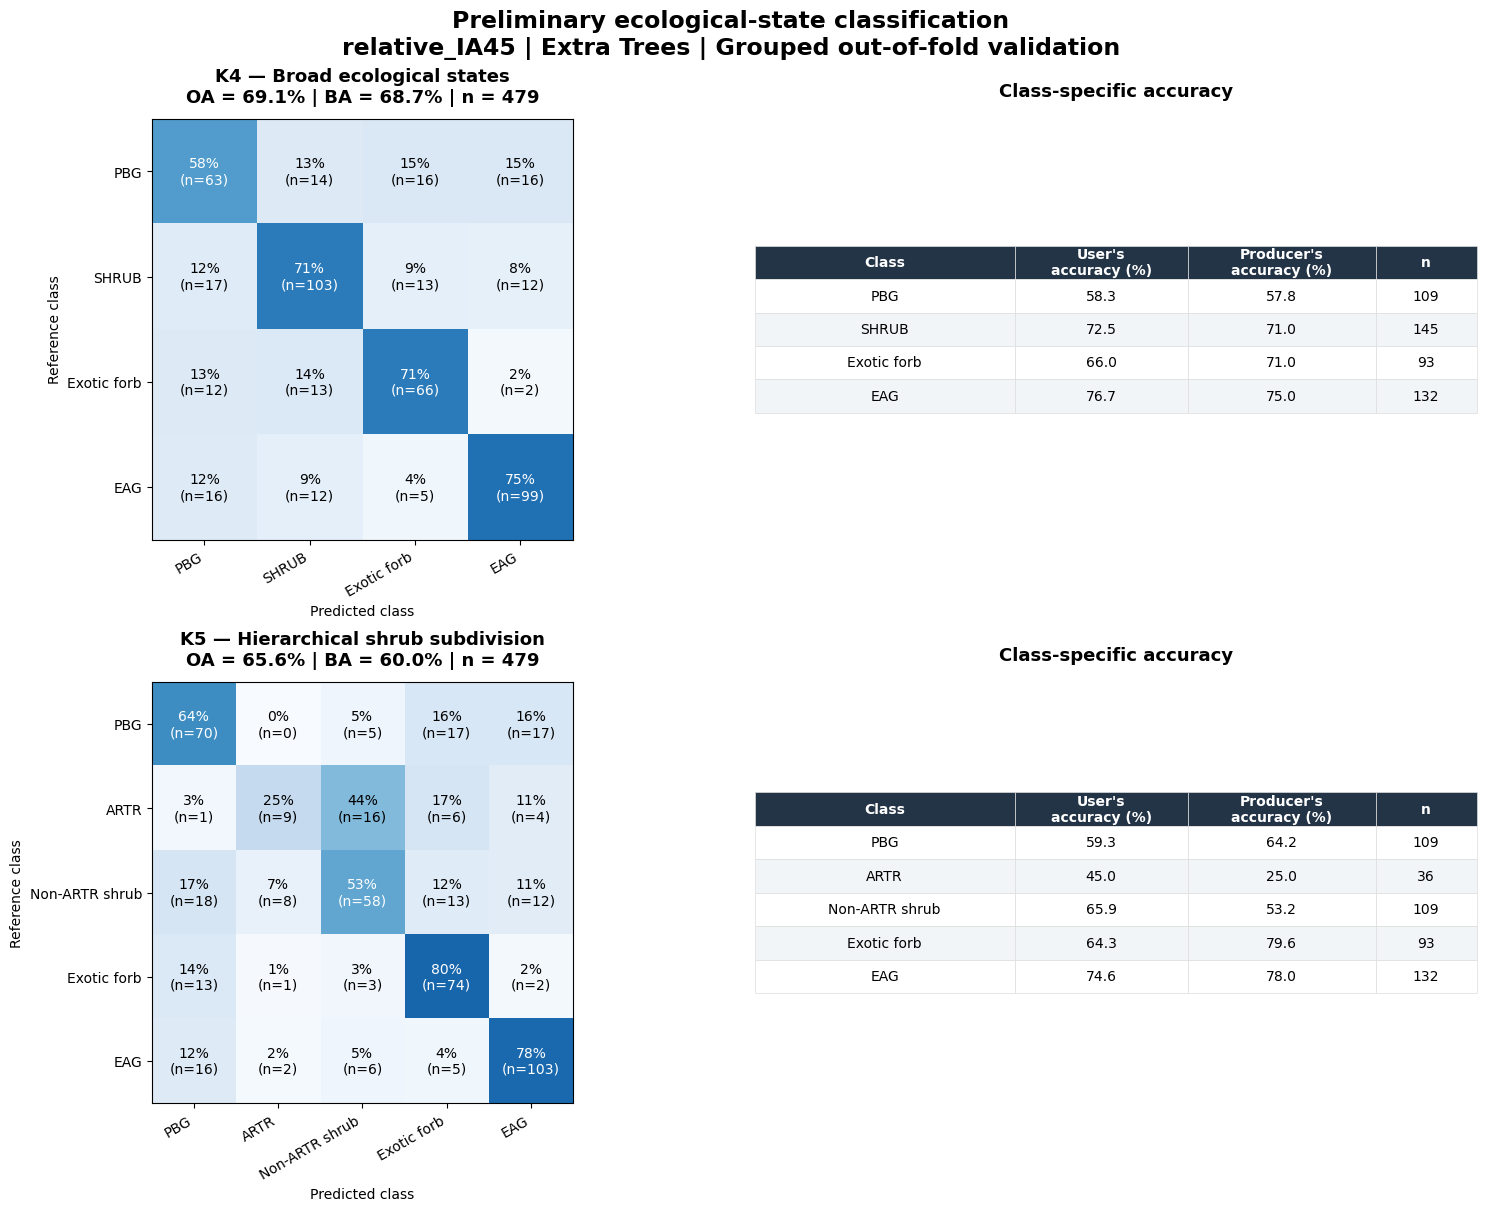

In [15]:

# ============================================================
# K4 / K5 CLASSIFICATION ACCURACY ASSESSMENT
# Confusion matrices + User's and Producer's Accuracy
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
FEATURE = "relative_IA45"  # or "raw_plus_ratios_IA75"
MODEL = "extra_trees"
K5_SCENARIO = "hierarchy_soft_K5"

pred = OOF[(FEATURE, MODEL)]

comparisons = [
    (
        "K4 — Broad ecological states",
        y4,
        pred["parent_K4"],
        K4_CODES,
        K4_LABELS,
    ),
    (
        "K5 — Hierarchical shrub subdivision",
        y5,
        pred[K5_SCENARIO],
        K5_CODES,
        K5_LABELS,
    ),
]

# ------------------------------------------------------------
# Figure layout
# ------------------------------------------------------------
fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 12),
    gridspec_kw={
        "width_ratios": [1.15, 1.1]
    },
    constrained_layout=True,
)

for row, (title, actual, predicted, codes, names) in enumerate(comparisons):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    labels = [names[c] for c in codes]

    # --------------------------------------------------------
    # Confusion matrix
    # --------------------------------------------------------
    cm = confusion_matrix(
        actual, predicted, labels=codes
    )

    row_totals = cm.sum(axis=1, keepdims=True)

    cm_norm = np.divide(
        cm,
        row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0,
    )

    oa = accuracy_score(actual, predicted)
    ba = balanced_accuracy_score(actual, predicted)

    ax = axes[row, 0]

    ax.imshow(
        cm_norm,
        cmap="Blues",
        vmin=0,
        vmax=1,
        aspect="equal",
    )

    for i in range(len(codes)):
        for j in range(len(codes)):

            value = cm_norm[i, j]
            count = cm[i, j]

            ax.text(
                j, i,
                f"{value:.0%}\n(n={count})",
                ha="center",
                va="center",
                fontsize=10,
                color="white" if value > 0.5 else "black",
            )

    ax.set_xticks(
        range(len(codes)),
        labels,
        rotation=30,
        ha="right",
    )
    ax.set_yticks(range(len(codes)), labels)

    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Reference class")

    ax.set_title(
        f"{title}\n"
        f"OA = {oa:.1%} | BA = {ba:.1%} | n = {len(actual)}",
        fontsize=13,
        fontweight="bold",
        pad=12,
    )

    # --------------------------------------------------------
    # User's and Producer's Accuracy
    # --------------------------------------------------------
    ua, pa, _, support = precision_recall_fscore_support(
        actual,
        predicted,
        labels=codes,
        zero_division=0,
    )

    metrics_df = pd.DataFrame({
        "Class": labels,
        "Users_accuracy_percent": ua * 100,
        "Producers_accuracy_percent": pa * 100,
        "Support": support,
    })

    ax_table = axes[row, 1]
    ax_table.axis("off")

    table_data = [
        [
            label,
            f"{u:.1f}",
            f"{p:.1f}",
            f"{int(n)}",
        ]
        for label, u, p, n in zip(
            labels, ua * 100, pa * 100, support
        )
    ]

    tbl = ax_table.table(
        cellText=table_data,
        colLabels=[
            "Class",
            "User's\naccuracy (%)",
            "Producer's\naccuracy (%)",
            "n",
        ],
        cellLoc="center",
        colLoc="center",
        loc="center",
        colWidths=[0.36, 0.24, 0.26, 0.14],
    )

    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.scale(1, 2.0)

    for (r, c), cell in tbl.get_celld().items():

        cell.set_edgecolor("#DDDDDD")
        cell.set_linewidth(0.5)

        if r == 0:
            cell.set_facecolor("#243447")
            cell.set_text_props(
                color="white",
                weight="bold",
            )
        elif r % 2 == 0:
            cell.set_facecolor("#F2F5F7")
        else:
            cell.set_facecolor("white")

    ax_table.set_title(
        "Class-specific accuracy",
        fontsize=13,
        fontweight="bold",
        pad=16,
    )

    # Save class metrics
    metrics_df.to_csv(
        OUTPUT_DIR / (
            f"{FEATURE}_{MODEL}_"
            f"{'K4' if row == 0 else 'K5'}_UA_PA.csv"
        ),
        index=False,
    )

# ------------------------------------------------------------
# Final formatting and export
# ------------------------------------------------------------
fig.suptitle(
    "Preliminary ecological-state classification\n"
    f"{FEATURE} | {MODEL.replace('_', ' ').title()} "
    "| Grouped out-of-fold validation",
    fontsize=17,
    fontweight="bold",
)

fig.savefig(
    OUTPUT_DIR / f"{FEATURE}_{MODEL}_K4_K5_accuracy.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_DIR / f"{FEATURE}_{MODEL}_K4_K5_accuracy.svg",
    bbox_inches="tight",
)

plt.show()
